In [1]:
from neuromodes import mbm as mbm
from neuromodes.io import fetch_example_surf

In [2]:
from scipy.io import loadmat

In [3]:
from importlib.resources import files, as_file
from nsbutils.plotting import plot_surf
from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf

# Load cortical surface mesh
surf, medmask = fetch_example_surf()

# Initialise solver with surface
solver = EigenSolver(surf, mask=medmask).solve(10)

print(solver)


EigenSolver
-----------
Surface mesh: 29696 vertices (2796 others masked out), 59147 triangles
Mass matrix: consistent
Stiffness matrix: homogeneous
Eigenmodes and eigenvalues: 10 computed


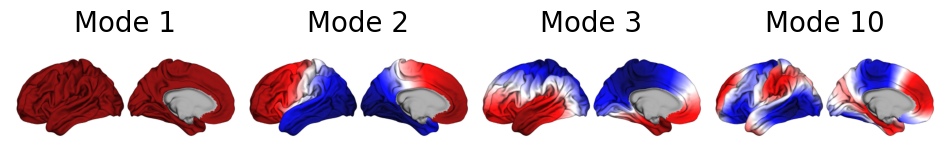

In [ ]:
modes_unmasked = solver.unmask_data(solver.emodes)

lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, modes_unmasked[:,[0,1,2,9]], labels=['Mode 1', 'Mode 2', 'Mode 3', 'Mode 10'], cmap='seismic')

In [5]:
face = loadmat('S255_tfMRI_raw_lh_motor_lf.mat')['maps']
hand = loadmat('S255_tfMRI_raw_lh_motor_lh.mat')['maps']

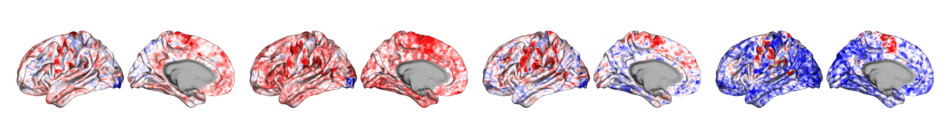

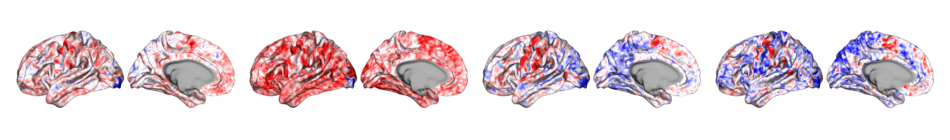

In [6]:
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, face[:,[0,1,2,9]], cmap='seismic')
    plot_surf(lh_surfpath, hand[:,[0,1,2,9]], cmap='seismic')

In [7]:
import numpy as np

nsubj = 255

z = np.zeros((nsubj,1))
o = np.ones((nsubj,1))
design = np.vstack((np.hstack((o, np.eye(nsubj))), np.hstack((-o, np.eye(nsubj)))))
response = np.vstack((face.T, hand.T))
contrast = np.hstack((np.array([[1,]]), np.zeros((1,nsubj))))
statTest = 'ttest'

# print(contrast)


In [8]:
statMap = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)

C:\Users\mehul\Documents\PhD\PYTHON\neuromodes\neuromodes\eigen.py:778: UserWarning: NaN values detected in data, which may cause issues with computations.
  warn("NaN values detected in data, which may cause issues with computations.")


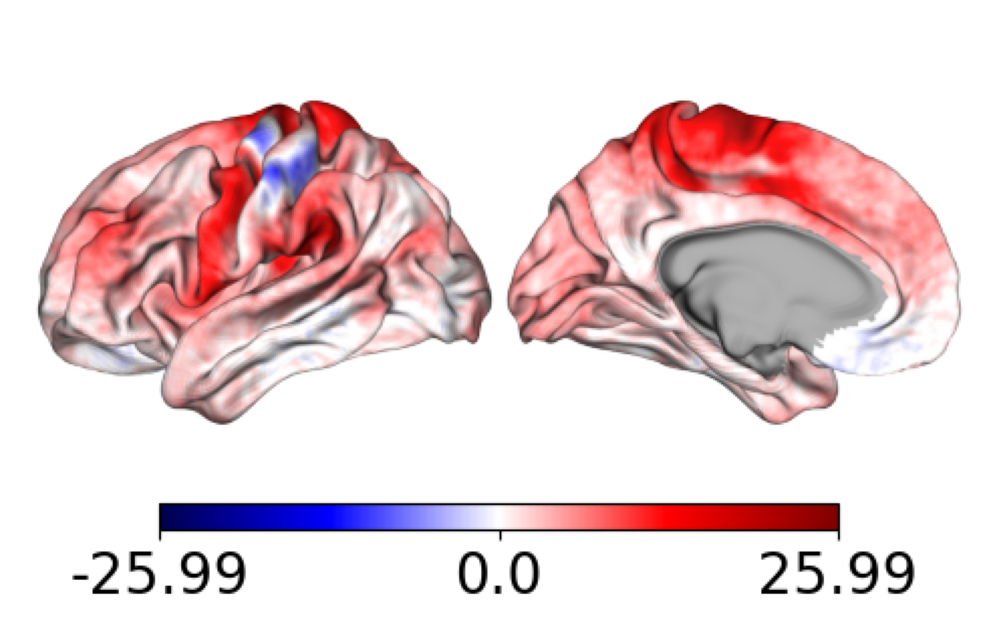

In [9]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, statMap, cmap='seismic', center=0, cbar=True, ax=axs)

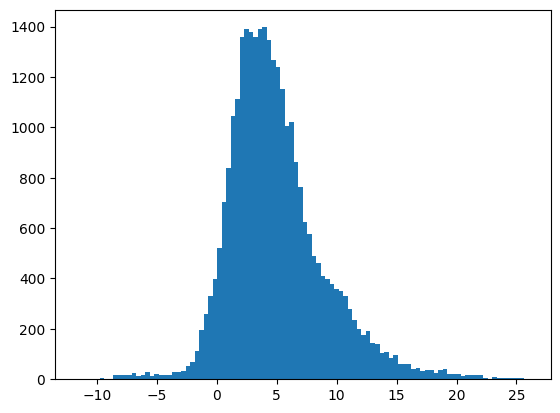

In [10]:


plt.hist(statMap, bins=100)
plt.show()

In [11]:
permMap = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, n_permutations=10, permutationMethod='shuffle_rows')

C:\Users\mehul\Documents\PhD\PYTHON\neuromodes\neuromodes\eigen.py:778: UserWarning: NaN values detected in data, which may cause issues with computations.
  warn("NaN values detected in data, which may cause issues with computations.")


In [12]:
pvals = mbm.mbm_calc_p_vals(statMap, permMap, 0.00, 'two-sided')[0]

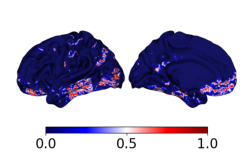

In [13]:
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, pvals, cmap='seismic', center=0.05, cbar=True, color_range=[0.00, 1.00])

In [14]:
np.min(pvals), np.max(pvals)

(np.float64(0.0), np.float64(1.0))